In [30]:
import numpy as np
from scipy.integrate import solve_ivp
import matplotlib.pyplot as plt
import seaborn as sns
sns.set()
%matplotlib inline 

Euler explicite à pas variable
------------

La fonction suivante code un exemple de schéma d'Euler explicite à pas variable : l'erreur commise est estimée à chaque itération et le pas de temps adapté de façon à garder cette erreur en dessous d'un seuil. Le pas reste compris entre dtmin et dtmax fixés par l'utilisateur et sort la solution échantillonnée à dtmax. La méthode d'estimation de l'erreur locale utilisée ici est justifiée dans le poly.

In [31]:
def solve_ivp_euler_explicit_variable_step(f, t0, x0, t_f, dtmin = 1e-16, dtmax = 0.01, atol = 1e-6, return_steps = False):
    dt = dtmax/10; # initial integration step
    ts, xs = [t0], [x0]  # storage variables
    t_steps, dt_steps = [], []  # internal time steps actually used (returned if return_steps)
    t = t0
    ti = 0  # internal time keeping track of time since latest storage point : must remain below dtmax
    x = x0
    while ts[-1] < t_f:
        while ti < dtmax:
            t_next, ti_next, x_next = t + dt, ti + dt, x + dt * f(x)
            x_back = x_next - dt * f(x_next)
            abs_error = np.linalg.norm(x_back-x)/2  # estimated local error (see course)
            dt_new = 0.9 * dt * np.sqrt(atol / abs_error) if abs_error > 0 else dtmax/2
            if dt_new < dtmin:
                raise ValueError("Time step below minimum")
            elif dt_new > dtmax/2:
                dt_new = dtmax/2
            if abs_error > atol and dt > dtmin:
                dt = dt_new  # step rejected : retry with a smaller step
                continue
            t_steps.append(t); dt_steps.append(dt)
            dt = dt_new
            t, ti, x = t_next, ti_next, x_next
        dt2DT = dtmax - ti # time left to dtmax
        t_next, ti_next, x_next = t + dt2DT, 0, x + dt2DT * f(x)
        ts = np.vstack([ts,t_next])
        xs = np.vstack([xs,x_next])
        t, ti, x = t_next, ti_next, x_next
    if return_steps:
        return (ts, xs.T, np.array(t_steps), np.array(dt_steps))
    return (ts, xs.T)


Par exemple, sur un oscillateur, le pas de temps "interne" s'adapte automatiquement à la pulsation $\omega$. Notons que la solution en sortie est toujours échantillonnées à dtmax, donc il faut diminuer ce paramètre si l'on veut plus de précision de visualisation.

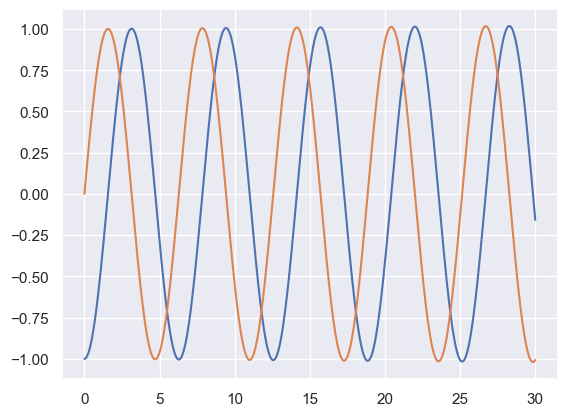

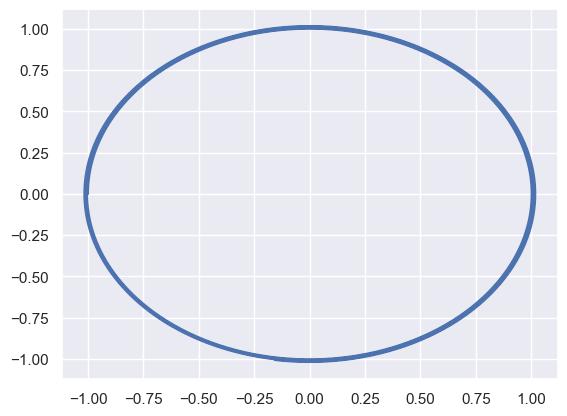

In [32]:
# Oscillateur 

omega = 1

def f(xy):
    x, y = xy
    return np.array([y, -omega*x])

t0, tf, x0 = 0.0, 30.0, np.array([-1.0, 0.0])

t, x = solve_ivp_euler_explicit_variable_step(f, t0, x0, tf)

plt.figure()
plt.plot(t, x[0])
plt.plot(t, x[1])
plt.grid(True)

plt.figure()
plt.plot(x[0],x[1])


On constate cependant que les solutions ne suivent pas une ellipse parfaite car l'énergie n'est pas conservée par l'algorithme. Pour ce type de système conservatif, il faudrait en fait un schéma symplectique. Voir plus bas.

Sur l'oscillateur, le pas interne est quasiment constant : rien ne justifie vraiment de l'adapter. L'intérêt apparaît sur des systèmes dont la "vitesse" varie beaucoup au cours du temps. Prenons l'oscillateur de **Van der Pol**
$$
\dot y_1 = y_2, \qquad \dot y_2 = \mu(1-y_1^2)\,y_2 - y_1,
$$
avec $\mu=10$ et $y(0)=(2,0)$. Pour $\mu$ grand, il présente des *oscillations de relaxation* : la trajectoire alterne entre des phases lentes, où elle suit de près une courbe en S dans le plan de phase, et des sauts rapides quasi verticaux d'une branche de cette courbe à l'autre. Le système est autonome : ce n'est pas le temps qui rend $f$ grande, c'est la trajectoire elle-même qui revient périodiquement dans les régions (au voisinage de $y_1=\pm1$) où $f$ et sa dérivée, donc l'erreur de consistance, explosent. On s'attend donc à ce que le pas se resserre à chaque saut et se relâche sur les phases lentes, indéfiniment et en phase avec le cycle limite. On utilise l'option `return_steps=True` pour récupérer les pas internes réellement utilisés.


8704 pas internes, dt min = 1.9e-04, dt max = 1.0e-01


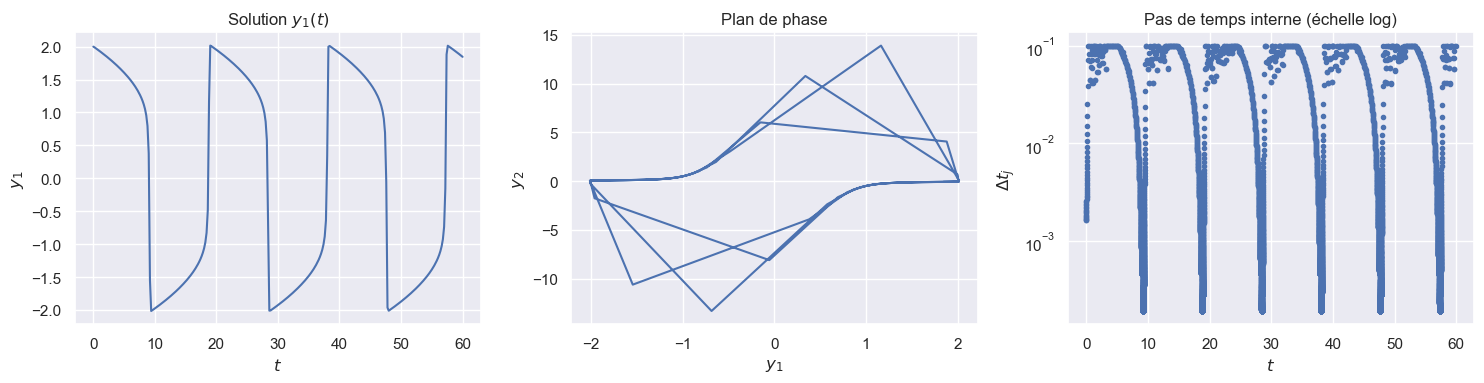

In [33]:
# Oscillateur de Van der Pol

mu = 10.0

def f_vdp(y):
    y1, y2 = y
    return np.array([y2, mu*(1 - y1**2)*y2 - y1])

t0, tf, y0 = 0.0, 60.0, np.array([2.0, 0.0])

t, y, t_steps, dt_steps = solve_ivp_euler_explicit_variable_step(
    f_vdp, t0, y0, tf, dtmin=1e-8, dtmax=0.2, atol=1e-4, return_steps=True)

print(f"{len(dt_steps)} pas internes, dt min = {dt_steps.min():.1e}, dt max = {dt_steps.max():.1e}")

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(15, 4))
ax1.plot(t, y[0]); ax1.set_xlabel("$t$"); ax1.set_ylabel("$y_1$"); ax1.set_title("Solution $y_1(t)$")
ax2.plot(y[0], y[1]); ax2.set_xlabel("$y_1$"); ax2.set_ylabel("$y_2$"); ax2.set_title("Plan de phase")
ax3.semilogy(t_steps, dt_steps, "."); ax3.set_xlabel("$t$"); ax3.set_ylabel("$\\Delta t_j$"); ax3.set_title("Pas de temps interne (échelle log)")
plt.tight_layout()


Le pas se resserre d'un facteur mille pendant chaque saut puis remonte jusqu'à `dtmax/2` sur les phases lentes : un pas fixe devrait être choisi à la plus petite de ces valeurs partout. Deux limites à garder en tête : cette stratégie ne contrôle que l'erreur *locale* (rien ne garantit l'erreur globale, qui dépend de la constante de stabilité $S(T)$), et pour $\mu$ plus grand encore le système devient franchement raide (voir ci-dessous) : le pas d'un schéma explicite s'effondrerait pendant les sauts et il faudrait passer à un schéma implicite.


# Système raide 

Les systèmes raides désignent des systèmes comprenant des dynamiques aux constantes de temps très différentes. Dans ce cas, le pas nécessaire pour simuler avec précision les dynamiques très rapides est si petit, qu'il est alors impossible de simuler assez longtemps pour observer les parties lentes. La particularité de ces systèmes est que cette décroissance du pas apparaît alors que la solution est parfaitement régulière, et non pas proche de singularités.

La coexistence de dynamiques très lentes à très rapides apparaît typiqument en cinétique chimique, par exemple la réaction de Robertson :
\begin{align*}
A & \stackrel{0.04}{\longrightarrow}  B \quad \text{(lente)} \\ 
B + B & \stackrel{3 \times 10^7}{\longrightarrow}  B + C \quad \text{(très rapide)}  \\
B + C & \stackrel{10^4}{\longrightarrow}  A + C  \quad \text{(rapide)} 
\end{align*}
modélisée par 
\begin{align*}
\dot{x}_a &= -0.04 x_a + 10^4 x_bx_c \\
\dot{x}_b &= 0.04 x_a - 10^4 x_bx_c - 3\times 10^7 x_b^2\\
\dot{x}_c &= 3\times 10^7 x_b^2
\end{align*}

Lorsqu'on applique le schéma d'Euler explicite à pas variable, le compromis précision/pas de temps devient impossible. 

In [34]:

def f(xabc):
    xa, xb, xc = xabc
    return np.array([-0.04 * xa + 1e4 * xb * xc, 0.04 * xa - 1e4 * xb * xc - 3e7 * xb**2,  3e7 * xb**2])

t0, tf, x0 = 0.0, 5.0, np.array([1.0, 0.0, 0.0])

t, x = solve_ivp_euler_explicit_variable_step(f, t0, x0, tf, dtmin = 1e-20, atol = 1)

plt.figure()
plt.plot(t, x[0])
plt.plot(t, x[1])
plt.plot(t, x[2])
plt.grid(True)

ValueError: Time step below minimum

Le remède est un schéma implicite. Le plus simple est Euler implicite à pas fixe, $x^{j+1} = x^j + \Delta t\, f(x^{j+1})$ : à chaque itération il faut résoudre une équation non linéaire en $x^{j+1}$, ce que l'on confie à `fsolve` (méthode de Newton), initialisée au point courant. Avec un pas de $0{,}01$ (le `dtmax` du solveur explicite, qui lui doit descendre en dessous de $10^{-20}$), la simulation passe sans difficulté : le pas n'est plus dicté par la stabilité mais par la précision souhaitée sur les dynamiques lentes. Attention cependant à ne pas prendre un pas trop grand : l'équation non linéaire a plusieurs racines (à cause du terme en $x_b^2$) et pour $\Delta t = 0{,}1$ Newton converge vers une racine non physique avec $x_b<0$.


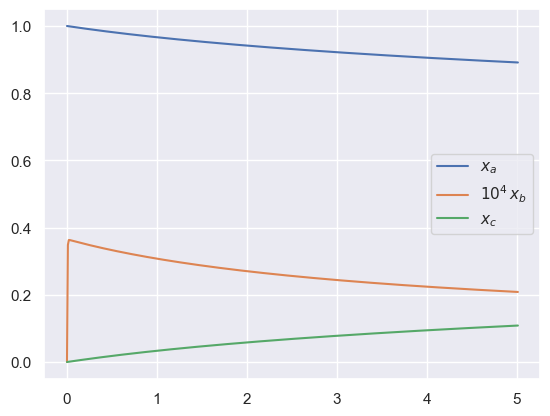

In [35]:
from scipy.optimize import fsolve

def solve_ivp_euler_implicit(f, t0, x0, tf, dt):
    ts, xs = [t0], [x0]
    while ts[-1] < tf:
        t, x = ts[-1], xs[-1]
        x_next = fsolve(lambda y: y - x - dt * f(y), x)  # résout x_next = x + dt f(x_next)
        ts.append(t + dt); xs.append(x_next)
    return np.array(ts), np.array(xs).T

t, x = solve_ivp_euler_implicit(f, t0, x0, tf, dt=0.01)

plt.figure()
plt.plot(t, x[0], label="$x_a$")
plt.plot(t, 1e4 * x[1], label="$10^4\, x_b$")
plt.plot(t, x[2], label="$x_c$")
plt.legend(); plt.grid(True)


Système hamiltonien 
=====================

Voir exercice "Euler Symplectique". On cherche à simuler
\begin{align*}
\dot{q} &= \nabla_p H(q,p) \\
\dot{p} &= - \nabla_q H(q,p)
\end{align*}
où $(q,p)\in \mathbb{R}^N \times \mathbb{R}^N$ et $H$ est le hamiltonien conservé le long des trajectoires. $N$ est typiquement le nombre de corps/particules, $q$ contient leurs positions généralisées et $p$ leur quantité de mouvement.

Par exemple, pour un oscillateur harmonique simple, $N=1$, et $H$ est l'énergie mécanique du type
$$
H(q,p) = \frac{1}{2m}p^2 + \frac{1}{2} k q^2
$$
ce qui donne
\begin{align*}
\dot{q} &= \frac{1}{m}p \\
\dot{p} &= - k q
\end{align*}
ou de manière équivalente, si on considère la vitesse $v$ au lieu de la quantité de mouvement $p=mv$,
\begin{align*}
\dot{q} &= v \\
\dot{v} &= - \frac{k}{m} q
\end{align*}

In [36]:
m = 1.0
k = 1.0
q0 = 1.0
p0 = m*0.0
t0, tf, dt = 0.0 , 60.0, 0.01

In [37]:
def solve_ivp_euler_symplectic(fp, fq, t0, q0, p0, dt, tf):
    ts, qs, ps = [t0], [q0], [p0]
    while ts[-1] < tf:
        t, q, p = ts[-1], qs[-1], ps[-1]
        t_next, q_next = t + dt, q + dt*fq(p)
        p_next = p + dt*fp(q_next)
        ts = np.vstack([ts,t_next])
        qs = np.vstack([qs,q_next])
        ps = np.vstack([ps,p_next])
    return (ts, qs.T, ps.T)

In [38]:
def fq(p):
    return 1/m*p

def fp(q):
    return -k*q

def fun(qp):
    q, p = qp
    return np.array([fq(p),fp(q)])

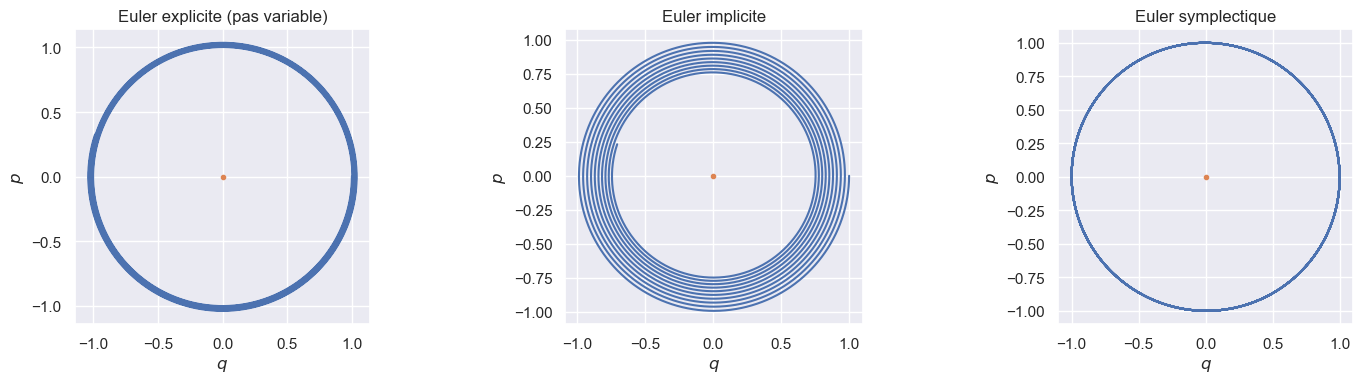

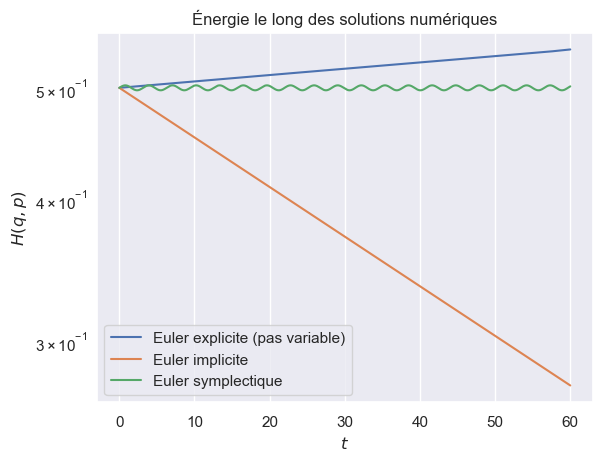

In [39]:
t_s, q, p = solve_ivp_euler_symplectic(fp, fq, t0, q0, p0, dt, tf)
t_e, qp_e = solve_ivp_euler_explicit_variable_step(fun, t0, np.array([q0, p0]), tf)
t_i, qp_i = solve_ivp_euler_implicit(fun, t0, np.array([q0, p0]), tf, dt)

def H(q, p):
    return p**2/(2*m) + k*q**2/2

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (qq, pp, titre) in zip(axes, [(qp_e[0], qp_e[1], "Euler explicite (pas variable)"),
                                      (qp_i[0], qp_i[1], "Euler implicite"),
                                      (q[0], p[0], "Euler symplectique")]):
    ax.plot(qq, pp); ax.plot([0.0], [0.0], '.')
    ax.set_xlabel("$q$"); ax.set_ylabel("$p$"); ax.set_title(titre); ax.set_aspect("equal")
plt.tight_layout()

plt.figure()
plt.semilogy(t_e, H(qp_e[0], qp_e[1]), label="Euler explicite (pas variable)")
plt.semilogy(t_i, H(qp_i[0], qp_i[1]), label="Euler implicite")
plt.semilogy(t_s, H(q[0], p[0]), label="Euler symplectique")
plt.xlabel("$t$"); plt.ylabel("$H(q, p)$"); plt.title("Énergie le long des solutions numériques")
plt.legend(); plt.grid(True)
plt.show()


Le hamiltonien $H$ est constant le long des vraies solutions, et la trajectoire est le cercle $H(q,p)=H(q_0,p_0)$. Les deux schémas d'Euler, explicite comme implicite, en sont incapables sur un temps long : l'un gagne de l'énergie à chaque révolution et spirale vers l'extérieur, l'autre en perd et spirale vers l'origine — et ce quel que soit le pas, seule la vitesse de dérive change (ici le pas variable de l'explicite la rend lente, mais elle est bien là). Le schéma symplectique n'est pas exact non plus : son énergie oscille à chaque révolution, mais sans dériver, et sa trajectoire reste sur une ellipse proche du cercle. C'est la quantité modifiée $H + \frac{\Delta t}{2}\,\dot q\,\dot p$ (voir l'exercice) qu'il conserve exactement, ce qui suffit pour simuler des temps arbitrairement longs. C'est ce même phénomène, à l'échelle du système solaire, qu'illustre la figure du cours.
